<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/05_%E6%A8%A1%E5%9E%8B%E5%8F%83%E6%95%B8/README.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05. 模型參數 (Model Parameters & Hyperparameters)

本範例透過繁體中文「廣告與銷售資料集」直觀對比：
- **內部參數 (Learnable Parameters)**：模型學到的權重係數 $w$ 與偏置截距 $b$。
- **外部超參數 (Hyperparameters)**：工程師設定的調節器（如 Ridge 回歸的正則化強度 $\alpha$）。
- **視覺化**：繪製不同超參數下的擬合直線變化。

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# --- 設定 Matplotlib / Seaborn 中文字型支援（Mac / Windows / Colab 通用）---
import glob
import os
import mplfonts
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False
print("繁體中文字型已成功載入！")


繁體中文字型已成功載入！


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge

# 讀取廣告與銷售資料集
df = pd.read_csv('廣告與銷售資料集.csv')
X = df[['廣告預算_萬元']]
y = df['產品銷售額_萬元']

print("=== 資料集預覽 ===")
print(df.head())


=== 資料集預覽 ===
   廣告預算_萬元  產品銷售額_萬元
0     21.9      76.2
1     47.8     140.4
2     37.9     127.7
3     31.9      94.6
4     12.0      50.3


In [4]:
# 1. 訓練普通線性回歸，取得內部參數
lr = LinearRegression()
lr.fit(X, y)

w = lr.coef_[0]
b = lr.intercept_

print("=== 模型自主學出的內部參數 ===")
print(f"學到的權重斜率 w (廣告效益係數): {w:.4f}")
print(f"學到的偏置截距 b (基本保底銷售): {b:.4f}")
print(f"預測方程式: 銷售額 = {w:.2f} * 廣告預算 + {b:.2f}")


=== 模型自主學出的內部參數 ===
學到的權重斜率 w (廣告效益係數): 2.8238
學到的偏置截距 b (基本保底銷售): 13.7719
預測方程式: 銷售額 = 2.82 * 廣告預算 + 13.77


=== 外部超參數對內部權重的影響 ===
寬鬆懲罰 (alpha=0.1) 學出的斜率 w:   2.8237
強力懲罰 (alpha=500.0) 學出的斜率 w: 2.6331 (權重被大幅抑制防止過擬合)


/Users/roberthsu2003/Documents/GitHub/machine_learning/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/roberthsu2003/Documents/GitHub/machine_learning/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(


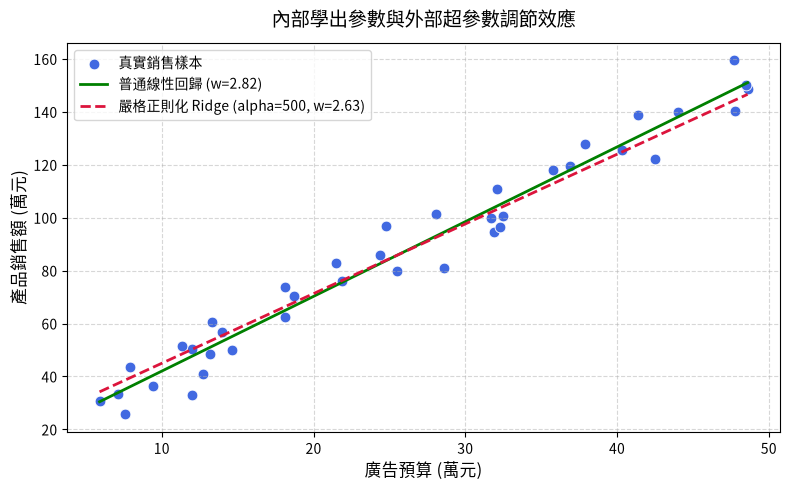

💡 觀念總結：內部參數由數據驅動自主學習，外部超參數則是工程師控制模型行為的控制旋鈕！


In [5]:
# 2. 調校外部超參數 (Ridge 正則化懲罰 alpha)
ridge_loose = Ridge(alpha=0.1).fit(X, y)      # 寬鬆超參數
ridge_strict = Ridge(alpha=500.0).fit(X, y)   # 嚴格超參數

print("=== 外部超參數對內部權重的影響 ===")
print(f"寬鬆懲罰 (alpha=0.1) 學出的斜率 w:   {ridge_loose.coef_[0]:.4f}")
print(f"強力懲罰 (alpha=500.0) 學出的斜率 w: {ridge_strict.coef_[0]:.4f} (權重被大幅抑制防止過擬合)")

# 3. 繪圖比較
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='廣告預算_萬元', y='產品銷售額_萬元', color='royalblue', label='真實銷售樣本', s=60)
x_line = np.linspace(df['廣告預算_萬元'].min(), df['廣告預算_萬元'].max(), 100).reshape(-1, 1)

plt.plot(x_line, lr.predict(x_line), color='green', linewidth=2, label=f'普通線性回歸 (w={w:.2f})')
plt.plot(x_line, ridge_strict.predict(x_line), color='crimson', linestyle='--', linewidth=2, label=f'嚴格正則化 Ridge (alpha=500, w={ridge_strict.coef_[0]:.2f})')

plt.title('內部學出參數與外部超參數調節效應', fontsize=14, pad=12)
plt.xlabel('廣告預算 (萬元)', fontsize=12)
plt.ylabel('產品銷售額 (萬元)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("💡 觀念總結：內部參數由數據驅動自主學習，外部超參數則是工程師控制模型行為的控制旋鈕！")
